In [1]:
import json
import os
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import pytz
%matplotlib widget

In [2]:
# load config json
with open('/home/ishani/LeoPNT/starlink_ofdm/Starloc/utils/config.json') as f:
    config = json.load(f)
    print('iq0_filepath:', config['paths']['iq0_filepath'])
    print('imudata_filepath:', config['paths']['imudata_filepath'])
    print('TLE_filepath:', config['paths']['TLE_filepath'])
    print('results_dirpath:', config['paths']['results_dirpath'])
    if not os.path.exists(config['paths']['results_dirpath']):
        os.makedirs(config['paths']['results_dirpath'])
    print('center_freq:', config['hw_parameters']['center_freq'])
    print('calibsig_freq:', config['hw_parameters']['calibsig_freq'])
    print('sample_rate:', config['hw_parameters']['sample_rate'])
    print('antenna_spacing_meters:', config['hw_parameters']['antenna_spacing_meters'])
    

iq0_filepath: /home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_04_19_33_freq_11_325G_bw_2.0M_ts_1709698773.3134246_inrx0.dat
imudata_filepath: /home/ishani/LeoPNT/USRP_data/3_5/imu_utctime_2024_03_06_04_19_12.txt
TLE_filepath: /home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_04_19_13_starlink.tle
results_dirpath: /home/ishani/LeoPNT/starlink_ofdm/Starloc/results/tmp
center_freq: 11325000000.0
calibsig_freq: 11325100000.0
sample_rate: 2000000.0
antenna_spacing_meters: 0.1325


In [3]:
### ============================================================ ###
### Define results dir and other parameters required throughout. ###
### ============================================================ ###

## Loading iq filepaths
iq_filepaths = [config['paths']['iq0_filepath'], config['paths']['iq0_filepath'].replace('inrx0', 'inrx1'), config['paths']['iq0_filepath'].replace('inrx0', 'inrx2')]
## Load date and start time of capture
date = iq_filepaths[0].split('_')[-12]+'_'+iq_filepaths[0].split('_')[-11]+'_'+iq_filepaths[0].split('_')[-10]
start_time = float(iq_filepaths[0].split('_')[-2]) # utc epoch second at time of capture

## Create folder to save results
curriqfile_results_dirpath = os.path.join(config['paths']['results_dirpath'], date)
print('curriqfile_results_dirpath:', curriqfile_results_dirpath)
if not os.path.exists(curriqfile_results_dirpath):
        os.makedirs(curriqfile_results_dirpath)

## Loading HW parameters
fc = config['hw_parameters']['center_freq']
tx_freq = config['hw_parameters']['calibsig_freq']
sample_rate = config['hw_parameters']['sample_rate']
d = config['hw_parameters']['antenna_spacing_meters']
lam = 299792458 / fc

## Get grount truth location
from utils.imu_data import IMUData
imu = IMUData(config['paths']['imudata_filepath'])
imu_data = imu.read_imu_data()
lat, lon, alt = imu.get_latlonalt_()
lat_gt, lon_gt, alt_gt = np.mean(lat), np.mean(lon), np.mean(alt)
orient = imu.get_attitude()
yaw, pitch, roll = np.mean(orient[2][-3000:-1]), np.mean(orient[1]), np.mean(orient[0])

print('lat_gt:', lat_gt, 'lon_gt:', lon_gt, 'alt_gt:', alt_gt)

# variables to keep track of the figure number
fig_no = 1

curriqfile_results_dirpath: /home/ishani/LeoPNT/starlink_ofdm/Starloc/results/tmp/6Mar2024_04_19
lat_gt: 40.1171203863895 lon_gt: -88.22639025706695 alt_gt: 191.86824283954982


date: 6Mar2024_04_19
start_time: 1709698773.3134246
capture_secs: 878.730304


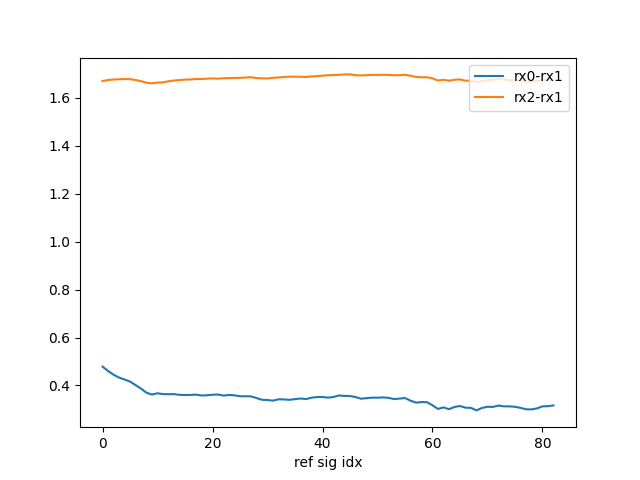

In [4]:
### =============================================== ###
### Extract Calibration Siganl phase from IQ files. ###
### =============================================== ###

from utils.calibration import CalibrationSignal

## Create instance of CalibrationSignal for each iq file. More details in utils/calibration.py
calib_signals = [CalibrationSignal(iq_filepaths[0], fc, tx_freq, sample_rate), CalibrationSignal(iq_filepaths[1], fc, tx_freq, sample_rate), CalibrationSignal(iq_filepaths[2], fc, tx_freq, sample_rate)]
## Getting calib/ref signal indexes (startidx, stopidx, transmit interval) for each time that the calibration signal is transmittes
calibsig_idxs = [calib_signals[0].get_all_refsigidx(), calib_signals[1].get_all_refsigidx(), calib_signals[2].get_all_refsigidx()]
## Calculate total secs of capture
capture_secs =  calibsig_idxs[0][-1][1] / sample_rate # seconds after start of capture when calibration signal stops transmitting

## Get phase of calibration signal at each calib/ref signal index
ref_sig_idxs = calibsig_idxs[0]
calibsig_phases = [calib_signals[0].get_refsig_phase(ref_sig_idxs), calib_signals[1].get_refsig_phase(ref_sig_idxs), calib_signals[2].get_refsig_phase(ref_sig_idxs)]
phase_offset_01 = np.unwrap(calibsig_phases[0]-calibsig_phases[1])
phase_offset_21 = np.unwrap(calibsig_phases[2]-calibsig_phases[1])

print('date:', date)
print('start_time:', start_time)
print('capture_secs:', capture_secs)

## Plotting phase difference between rx0-rx1 and rx2-rx1 calibration signals

plt.figure(fig_no)
plt.plot(phase_offset_01, label='rx0-rx1')
plt.plot(phase_offset_21, label='rx2-rx1')
plt.xlabel('ref sig idx')
plt.legend(loc='upper right')
plt.show()
fig_no += 1

In [5]:
## Save info to mat file
sio.savemat(os.path.join(curriqfile_results_dirpath, 'info.mat'), {'IQ_Sample_file_0': iq_filepaths[0],'sample_rate': sample_rate, 'date': date, 'start_time': start_time, 'ref_sig_idx': ref_sig_idxs, 't_end': capture_secs, 'phase_offset_01': phase_offset_01, 'phase_offset_21': phase_offset_21, 'lat_gt': lat_gt, 'lon_gt': lon_gt, 'alt_gt': alt_gt})

In [6]:
### ============================================================= ###
### Detect and track centertones. Also get the associated phases. ###
### ============================================================= ###
import matlab.engine
eng = matlab.engine.start_matlab()
eng.workspace['date_'] = os.path.join(config['paths']['results_dirpath'], date)
eng.run('phase_from_bin_track.m', nargout=0)
eng.quit()


Centertone detection and tracking: done, result saved in /home/ishani/LeoPNT/starlink_ofdm/Starloc/results/tmp/6Mar2024_04_19/res.mat, total 16779 points


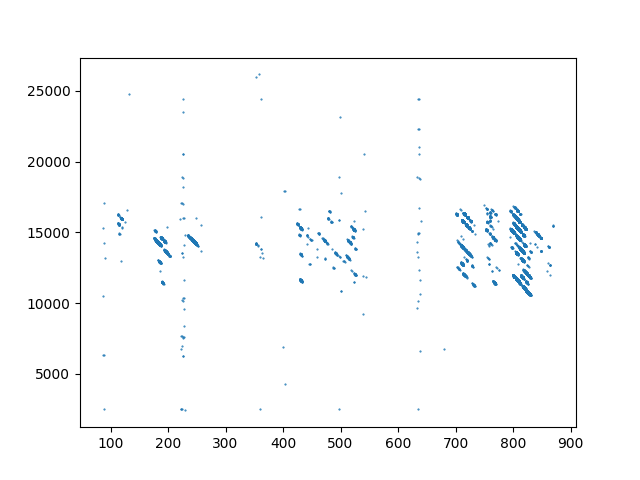

In [8]:
## load the centertrone tracking results from the mat file and plot
res = sio.loadmat(os.path.join(curriqfile_results_dirpath, 'res.mat'))['res']
plt.figure(fig_no)
plt.plot(res[:, 0].real, res[:, 1].real, '.', markersize=1)
plt.show()
fig_no += 1

In [6]:
sio.loadmat(os.path.join(curriqfile_results_dirpath, 'info.mat'))

{'__header__': b'MATLAB 5.0 MAT-file Platform: posix, Created on: Sun May  5 15:28:08 2024',
 '__version__': '1.0',
 '__globals__': [],
 'IQ_Sample_file_0': array(['/home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_04_19_33_freq_11_325G_bw_2.0M_ts_1709698773.3134246_inrx0.dat'],
       dtype='<U112'),
 'sample_rate': array([[2000000.]]),
 'date': array(['6Mar2024_04_19'], dtype='<U14'),
 'start_time': array([[1.70969877e+09]]),
 'ref_sig_idx': array([[1.38936320e+07, 1.50405120e+07, 5.73440000e-01],
        [3.51442560e+07, 3.62911360e+07, 5.73440000e-01],
        [5.63948800e+07, 5.75417600e+07, 5.73440000e-01],
        [7.76127360e+07, 7.87923840e+07, 5.89824000e-01],
        [9.88633600e+07, 1.00043008e+08, 5.89824000e-01],
        [1.20113984e+08, 1.21293632e+08, 5.89824000e-01],
        [1.41364608e+08, 1.42544256e+08, 5.89824000e-01],
        [1.62615232e+08, 1.63794880e+08, 5.89824000e-01],
        [1.83865856e+08, 1.85012736e+08, 5.73440000e-01],
        [2.05116480e+08, 2.062

In [9]:
### ======================================================================================================== ###
### Use ground truth location to get doppler tracks for all visible satellites within the capture timeframe. ###                                         ###
### ======================================================================================================== ###

from utils.sat_simulation import faster_doppler_sim

sim_start_time = start_time
t_end = sio.loadmat(os.path.join(curriqfile_results_dirpath, 'info.mat'))['t_end'][0][0]
lat_gt, lon_gt = (sio.loadmat(os.path.join(curriqfile_results_dirpath, 'info.mat'))['lat_gt'][0][0], 
                sio.loadmat(os.path.join(curriqfile_results_dirpath, 'info.mat'))['lon_gt'][0][0])

sim_end_time = sim_start_time+t_end
sat_dopp_dict, t_list = faster_doppler_sim(date=date, 
                                           tle_path=config['paths']['TLE_filepath'], 
                                           fc=fc, 
                                           t_start=sim_start_time, 
                                           t_stop=sim_end_time, 
                                           t_step=1, 
                                           ground_station=(lat_gt, lon_gt))

output_doppler_file = os.path.join(curriqfile_results_dirpath, "output_doppler.mat")
sio.savemat(output_doppler_file, {'sat_dopp_dict': sat_dopp_dict, 't_list': t_list})

number of Starlink satellites loaded 5539
Duration in secs:  878.7303040027618


KeyboardInterrupt: 

In [4]:
### ==================================================================== ###
### Separate out centertones per sat from the entire set of centertones. ###
### ==================================================================== ###

import matlab.engine
eng = matlab.engine.start_matlab()
eng.workspace['date_'] = os.path.join(config['paths']['results_dirpath'], date)
eng.run('phase_from_bin.m', nargout=0)
eng.quit()

(2030,) (1314,)
(1859,) (901,)
(438,) (253,)
(147,) (125,)
(258,) (231,)
(2142,) (1458,)
(383,) (335,)
(11837,) (4353,)


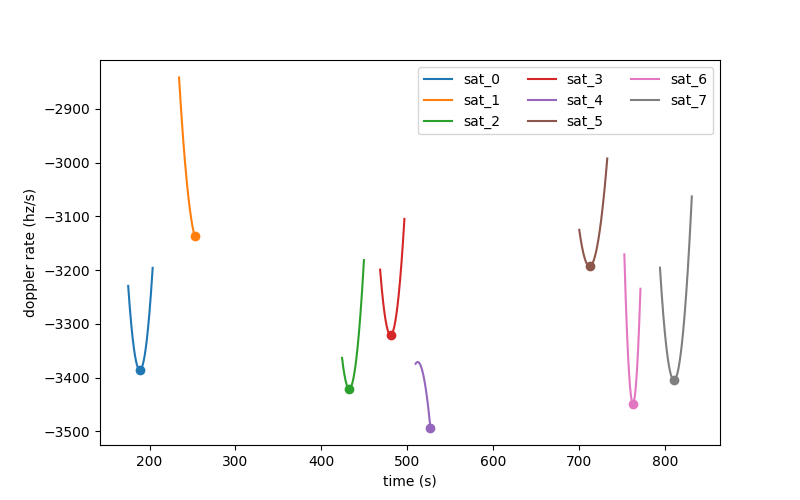

In [4]:
### ============================================================= ###
### Blind identification of satellite and verifying its accuracy. ###
### ============================================================= ###

# Step 1: get time at which each satellite is at max elevation
from utils.helper import diff_discrete_doppler

dopp_track_main = sio.loadmat(os.path.join(curriqfile_results_dirpath, 'doppler_track.mat'))['dopp_track_main_dict'][0]
max_elev_time_arr, dopp_coeff_list, is_middle_arr = [], [], [] # list to store time of max elevation of visible sat, doppler track coefficients obtained from polynomial fit and whether the sat is in the middle of the capture
median_time_arr = []
plt.figure(fig_no, figsize=(8, 5))
for sat_num, dopp_track in enumerate(dopp_track_main):
    print(dopp_track[:,0].real.shape, np.unique(dopp_track[:,0].real).shape)
    # differentiate the doppler track to get the rate of change of doppler
    dopp_rate, dopp_coeff = diff_discrete_doppler(dopp_track)
    median_time_arr.append(np.median(np.unique(dopp_track[:,0].real)))
    dopp_coeff_list.append(dopp_coeff)
    t_diff = dopp_rate[:, 0]
    dopp_diff = dopp_rate[:, 1]
    # Find the time at which the rate of change of doppler is minimum. This is the time at which the satellite is at max elevation
    max_elev_time_idx = np.argmin(dopp_diff)
    max_elev_time_arr.append(t_diff[max_elev_time_idx])
    # Check if the satellite is in the middle of the capture and append to is_middle_arr
    is_middle_arr.append(max_elev_time_idx != 0 and max_elev_time_idx != len(dopp_diff)-1)

    plt.plot(t_diff, dopp_diff, label='sat_'+str(sat_num))
    plt.scatter(t_diff[max_elev_time_idx], dopp_diff[max_elev_time_idx])
is_middle_arr = np.array(is_middle_arr)
max_elev_time_arr = np.array(max_elev_time_arr)
plt.xlabel('time (s)')
plt.ylabel('doppler rate (hz/s)')
plt.legend(loc='upper right',ncols=3)
fig_no += 1
plt.show()

/home/ishani/LeoPNT/starlink_ofdm/Starloc/utils/satid_blind_identification.py:179: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


Initial number of candidate location clusters: 2865
Possible: 431
Centroid of group  0 : [  35.70800974 -116.87324976]
sats in group: ['STARLINK-2580', 'STARLINK-30606', 'STARLINK-31198', 'STARLINK-1596', 'STARLINK-1231', 'STARLINK-30421', 'STARLINK-5450', 'STARLINK-1605']
Centroid of group  1 : [  37.67922604 -104.87097761]
sats in group: ['STARLINK-1437', 'STARLINK-5782', 'STARLINK-5696', 'STARLINK-30951', 'STARLINK-30039', 'STARLINK-3866', 'STARLINK-3051', 'STARLINK-1899']
Centroid of group  2 : [  37.67922604 -104.87097761]
sats in group: ['STARLINK-1437', 'STARLINK-5782', 'STARLINK-5696', 'STARLINK-30951', 'STARLINK-30521', 'STARLINK-3866', 'STARLINK-3051', 'STARLINK-1899']
Centroid of group  3 : [  39.44403718 -104.18720945]
sats in group: ['STARLINK-30960', 'STARLINK-30956', 'STARLINK-5696', 'STARLINK-1453', 'STARLINK-30039', 'STARLINK-5051', 'STARLINK-3866', 'STARLINK-1899']
Centroid of group  4 : [  39.44403718 -104.18720945]
sats in group: ['STARLINK-30960', 'STARLINK-30956',

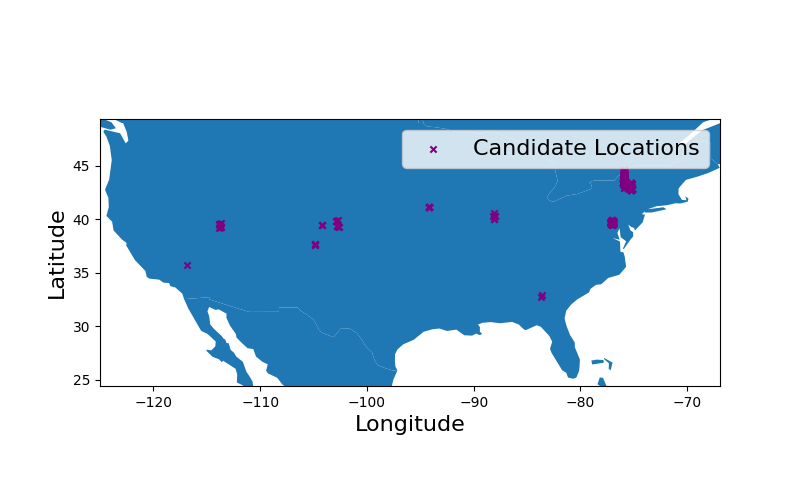

In [5]:
# Step 2: get candidate coarse_gs locations based on the time of max elevation

start_time_datetime = datetime.fromtimestamp(start_time, tz=pytz.utc)
tracked_peaks = sio.loadmat(os.path.join(curriqfile_results_dirpath, 'phase_comp.mat'))['dopp_track_dict'][0]

from utils.satid_blind_identification import get_candidate_locs_jida
search_radius = 220 # in km
fig = plt.figure(fig_no, figsize=(8,5))
ax = fig.add_subplot(1,1,1)
gs_groups, coarse_gs, sat_groups = get_candidate_locs_jida(start_time_datetime, max_elev_time_arr, is_middle_arr, config['paths']['TLE_filepath'], search_dist_bound=search_radius, fig_pointer=(fig, ax))
ax.legend(fontsize=16)
ax.set_xlabel('Longitude', fontsize=16)
ax.set_ylabel('Latitude', fontsize=16)
plt.show()
fig_no += 1

In [6]:
# Step 3: compare the observed phase with simulated phase for sat_groups, i.e, satellites associated each candidate coarse_gs location

from utils.satid_blind_identification import get_phase_diff_params_allsatsingroups_jida, sat_phasedopp_refined_coarsegs
from utils.helper import get_distkm_latlon_coordinates

slope_mes = sio.loadmat(os.path.join(curriqfile_results_dirpath, 'doppler_track.mat'))['slope_mes']
phase_slope = get_phase_diff_params_allsatsingroups_jida(gs_groups, coarse_gs, sat_groups, max_elev_time_arr+start_time, config['paths']['TLE_filepath'], 0, pitch, roll, d, lam)
phase_slope = np.array(phase_slope)

coarse_gs_lat, coarse_gs_lon,  coarsegs_idx = sat_phasedopp_refined_coarsegs(gs_groups, coarse_gs, sat_groups, phase_slope, slope_mes, dopp_coeff_list, dopp_track_main, start_time)

gt_id_dict = sio.loadmat(os.path.join(curriqfile_results_dirpath,'phase_comp.mat'))['id_dict'][0]
print('Coarse location error in kilometers :', get_distkm_latlon_coordinates([lat_gt, lon_gt], [coarse_gs_lat, coarse_gs_lon]))
for j in range(len(gt_id_dict)):
    print(gt_id_dict[j][0] + ': ', sat_groups[coarsegs_idx][j].name == gt_id_dict[j][0])

sio.savemat(os.path.join(curriqfile_results_dirpath, 'blind_id.mat'), {'coarse_lat': coarse_gs_lat, 'coarse_lon': coarse_gs_lon})

  0%|          | 0/431 [00:00<?, ?it/s]

100%|██████████| 431/431 [00:15<00:00, 27.00it/s]


Best Coarse GS: IDX =  102 [LAT, LON]=  [ 40.32196238 -88.17100594]
Coarse location error in kilometers : [23.25773921]
STARLINK-3505:  True
STARLINK-5749:  True
STARLINK-3361:  True
STARLINK-4559:  True
STARLINK-3507:  True
STARLINK-5799:  True
STARLINK-3501:  True
STARLINK-4553:  True
